# 위고하이 풋살 데이터 추가 분석

기존 프로젝트:
https://github.com/YuNi-100/wgh-futsal-qa

목적:
기존 경기 수·승률·득실점 합계 분석에 경기당 평균,
승률의 신뢰구간, 최근 5경기 이동평균을 추가한다.

분석 질문:
1. 경기 수를 고려해도 월별 경기력에 차이가 있을까?
2. 월별 승률은 표본 수에 따라 얼마나 불확실할까?
3. 최근 5경기 평균 득실차는 어떻게 변했을까?

In [1]:
import io
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import files

Path("images").mkdir(exist_ok=True)

uploaded = files.upload()

csv_names = [
    name for name in uploaded
    if name.lower().endswith(".csv")
]

if len(csv_names) != 1:
    raise ValueError("경기 기록 CSV 파일을 한 개 선택해주세요.")

filename = csv_names[0]

df = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    encoding="utf-8-sig"
)

print("파일명:", filename)
print("행·열 개수:", df.shape)
print("열 이름:", df.columns.tolist())

display(df.head())

Saving wgh-analysis.csv to wgh-analysis.csv
파일명: wgh-analysis.csv
행·열 개수: (10, 8)
열 이름: ['매치 ID', '경기 날짜', '우리 팀', '상대팀', '리그', '우리 득점', '상대 득점', '장소']


,매치 ID,경기 날짜,우리 팀,상대팀,리그,우리 득점,상대 득점,장소
0,16,2025-03-30T00:00:00.000,WGH 은평,천호[WGH],NaN,2,2,언더플레이 풋살파크 B구장
1,3,2026-08-18T00:00:00.000,WGH 은평,YDP,친선경기,3,6,대림운동장
2,5,2026-09-17T00:00:00.000,WGH 은평,EPI,NaN,8,1,효자풋살장
3,30,2026-09-20T00:00:00.000,WGH 은평,WGH 성동,위리그,2,1,언더플레이 풋살파크 구장A
4,29,2026-09-20T00:00:00.000,WGH 은평,WGH 천호,위리그,1,0,언더플레이 풋살파크 구장A


In [2]:
# 필요한 열 확인
required = [
    "매치 ID", "경기 날짜", "우리 득점", "상대 득점"
]

missing_columns = set(required) - set(df.columns)
if missing_columns:
    raise ValueError(f"필요한 열이 없습니다: {missing_columns}")

matches = df.copy()

# 날짜·점수를 분석 가능한 형식으로 변환
matches["경기 날짜"] = pd.to_datetime(
    matches["경기 날짜"], errors="coerce"
)

for column in ["우리 득점", "상대 득점"]:
    matches[column] = pd.to_numeric(
        matches[column], errors="coerce"
    )

# 중복·결측 확인
print("전체 경기 수:", len(matches))
print("중복 매치 ID:", matches["매치 ID"].duplicated().sum())

display(
    matches[required].isna().sum().to_frame("결측치 수")
)

# 문제가 있으면 임의로 삭제하지 않고 중단
assert matches["매치 ID"].notna().all(), "매치 ID를 확인하세요."
assert not matches["매치 ID"].duplicated().any(), "중복 경기를 확인하세요."
assert matches[required].notna().all().all(), "날짜·점수 결측치를 확인하세요."

scores = matches[["우리 득점", "상대 득점"]]
assert (scores >= 0).all().all(), "음수 점수를 확인하세요."
assert (scores % 1 == 0).all().all(), "정수가 아닌 점수를 확인하세요."

# 리그 미기록은 별도 표시
matches["리그"] = (
    matches["리그"]
    .replace(r"^\s*$", pd.NA, regex=True)
    .fillna("미기록")
)

# 같은 날짜는 매치 ID 순으로 정렬
matches = matches.sort_values(
    ["경기 날짜", "매치 ID"]
).reset_index(drop=True)

# 추가 분석용 변수
matches["월"] = matches["경기 날짜"].dt.to_period("M").astype(str)
matches["득실차"] = matches["우리 득점"] - matches["상대 득점"]
matches["승리"] = matches["득실차"] > 0

print("\n분석 기간:",
      matches["경기 날짜"].min().date(),
      "~",
      matches["경기 날짜"].max().date())

print("전처리 완료")
display(matches)

전체 경기 수: 10
중복 매치 ID: 0


,결측치 수
매치 ID,0
경기 날짜,0
우리 득점,0
상대 득점,0



분석 기간: 2025-03-30 ~ 2026-11-03
전처리 완료


,매치 ID,경기 날짜,우리 팀,상대팀,리그,우리 득점,상대 득점,장소,월,득실차,승리
0,16,2025-03-30,WGH 은평,천호[WGH],미기록,2,2,언더플레이 풋살파크 B구장,2025-03,0,False
1,3,2026-08-18,WGH 은평,YDP,친선경기,3,6,대림운동장,2026-08,-3,False
2,5,2026-09-17,WGH 은평,EPI,미기록,8,1,효자풋살장,2026-09,7,True
3,29,2026-09-20,WGH 은평,WGH 천호,위리그,1,0,언더플레이 풋살파크 구장A,2026-09,1,True
4,30,2026-09-20,WGH 은평,WGH 성동,위리그,2,1,언더플레이 풋살파크 구장A,2026-09,1,True
5,32,2026-10-14,WGH 은평,살림 FC,친선경기,3,4,상암 DMC 실내 A구장,2026-10,-1,False
6,25,2026-10-20,WGH 은평,FC SSAP,친선경기,3,8,월드컵 경기기장,2026-10,-5,False
7,26,2026-10-25,WGH 은평,WGH 다산,위리그,0,1,언더플레이 풋살파크 B구장,2026-10,-1,False
8,27,2026-10-25,WGH 은평,WGH 왕십리,위리그,0,3,언더플레이 풋살파크 구장A,2026-10,-3,False
9,31,2026-11-03,WGH 은평,FC 아리아,친선경기,3,4,월드컵 풋살장 C,2026-11,-1,False


## 데이터 확인 및 전처리

내려받은 CSV에는 경기 기록 10건이 있다.
날짜와 점수를 변환하고 매치 ID 중복·결측·점수 범위를 확인했다.
리그가 비어 있는 2건은 삭제하지 않고 ‘미기록’으로 표시했다.

분석 결과는 이 CSV에 포함된 등록 경기만 설명한다.
월별 경기 수가 적을 수 있으므로 평균과 승률을 해석할 때
경기 수를 함께 확인한다.

## 차트 1. 월별 경기당 평균 득점·실점

질문: 월마다 경기 수가 다른 점을 고려하면,
경기당 평균 득점과 실점은 어떻게 달라질까?

추가 기법: 월별 득점·실점 합계를 해당 월의 경기 수로 나눈다.

분석 기준: CSV에 등록된 10경기를 사용하며,
기록이 있는 월만 표시한다.
경기 시간과 상대팀 수준의 차이는 보정하지 않는다.

In [3]:
!apt-get -qq install -y fonts-nanum

import matplotlib.font_manager as fm

font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(font_path)

plt.rcParams["font.family"] = fm.FontProperties(
    fname=font_path
).get_name()
plt.rcParams["axes.unicode_minus"] = False

Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


,경기수,총득점,총실점,평균득점,평균실점
월,,,,,
2025-03,1,2,2,2.00,2.00
2026-08,1,3,6,3.00,6.00
2026-09,3,11,2,3.67,0.67
2026-10,4,6,16,1.50,4.00
2026-11,1,3,4,3.00,4.00


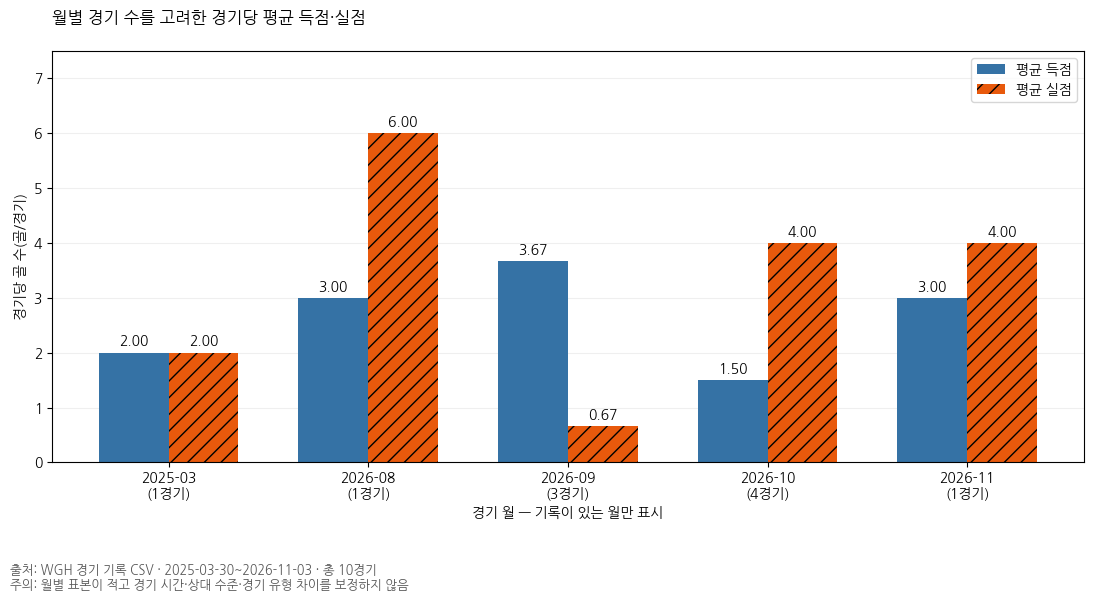

읽은 결과: 등록된 경기 기준으로 2026-09의 경기당 평균 득점이 3.67골로 가장 높았으며, 해당 월의 기록은 3경기였다.


In [4]:
import numpy as np

# 월별 합계와 경기당 평균을 함께 계산
monthly = (
    matches.groupby("월")
    .agg(
        경기수=("매치 ID", "nunique"),
        총득점=("우리 득점", "sum"),
        총실점=("상대 득점", "sum")
    )
    .sort_index()
)

monthly["평균득점"] = monthly["총득점"] / monthly["경기수"]
monthly["평균실점"] = monthly["총실점"] / monthly["경기수"]

# 집계 검산
assert monthly["경기수"].sum() == len(matches)
assert monthly["총득점"].sum() == matches["우리 득점"].sum()
assert monthly["총실점"].sum() == matches["상대 득점"].sum()

display(monthly.round(2))

# 월별 경기 수를 라벨에 표시
x = np.arange(len(monthly))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

scored_bars = ax.bar(
    x - width / 2,
    monthly["평균득점"],
    width,
    label="평균 득점",
    color="#3572A5"
)

conceded_bars = ax.bar(
    x + width / 2,
    monthly["평균실점"],
    width,
    label="평균 실점",
    color="#E8590C",
    hatch="//"
)

ax.bar_label(scored_bars, fmt="%.2f", padding=3)
ax.bar_label(conceded_bars, fmt="%.2f", padding=3)

ax.set_xticks(
    x,
    [
        f"{month}\n({int(row['경기수'])}경기)"
        for month, row in monthly.iterrows()
    ]
)

ax.set_title(
    "월별 경기 수를 고려한 경기당 평균 득점·실점",
    loc="left",
    pad=20
)
ax.set_xlabel("경기 월 — 기록이 있는 월만 표시")
ax.set_ylabel("경기당 골 수(골/경기)")
ax.set_ylim(
    0,
    monthly[["평균득점", "평균실점"]].to_numpy().max() * 1.25
)
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

start = matches["경기 날짜"].min().strftime("%Y-%m-%d")
end = matches["경기 날짜"].max().strftime("%Y-%m-%d")

fig.text(
    0.01, 0.01,
    f"출처: WGH 경기 기록 CSV · {start}~{end} · 총 {len(matches)}경기\n"
    "주의: 월별 표본이 적고 경기 시간·상대 수준·경기 유형 차이를 보정하지 않음",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.10, 1, 1])

fig.savefig(
    "images/01_monthly_average_goals.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 결과 문장 자동 생성
peak_month = monthly["평균득점"].idxmax()
row = monthly.loc[peak_month]

print(
    f"읽은 결과: 등록된 경기 기준으로 {peak_month}의 "
    f"경기당 평균 득점이 {row['평균득점']:.2f}골로 가장 높았으며, "
    f"해당 월의 기록은 {int(row['경기수'])}경기였다."
)

읽은 결과: 등록된 경기 기준으로 2026-09의 경기당 평균 득점이 3.67골로 가장 높았으며, 해당 월의 기록은 3경기였다.

## 차트 2. 월별 승률과 95% 신뢰구간

질문: 월별 승률은 경기 수에 따라 얼마나 불확실할까?

추가 기법: Wilson 방법으로 승률의 95% 신뢰구간을 계산한다.

승률은 승리 경기 수 ÷ 전체 경기 수로 계산한다.
무승부도 분모에 포함한다.
기록이 있는 월만 표시하며, 월별 경기 수를 함께 밝힌다.

,경기수,승리수,승률(%),95% 하한(%),95% 상한(%)
월,,,,,
2025-03,1,0,0.0,0.00,79.35
2026-08,1,0,0.0,0.00,79.35
2026-09,3,3,100.0,43.85,100.00
2026-10,4,0,0.0,0.00,48.99
2026-11,1,0,0.0,0.00,79.35


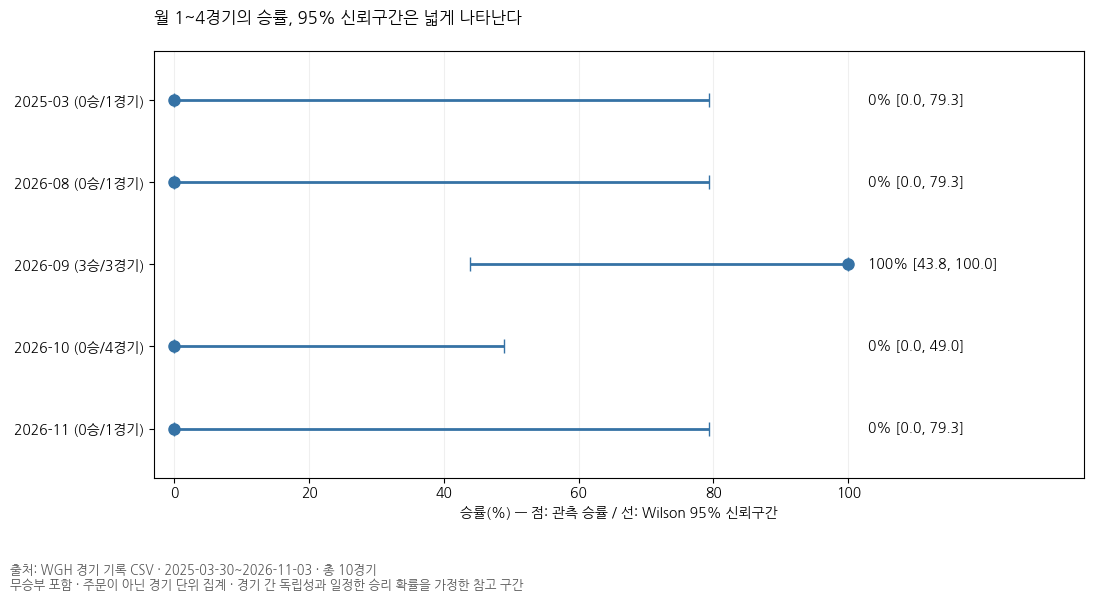

읽은 결과: 2026년 9월은 3경기 모두 승리해 관측 승률이 100%였지만, Wilson 95% 신뢰구간은 43.8~100.0%로 넓었다.
주의: 경기 수가 적고 상대팀과 경기 유형이 달라 이 구간을 미래 승률이나 월별 실력 차이의 확정적인 근거로 해석하지 않는다.


In [5]:
# 월별 경기 수와 승리 수
win_summary = (
    matches.groupby("월")
    .agg(
        경기수=("매치 ID", "nunique"),
        승리수=("승리", "sum")
    )
    .sort_index()
)

n = win_summary["경기수"].to_numpy(dtype=float)
wins = win_summary["승리수"].to_numpy(dtype=float)
p = wins / n

# Wilson 95% 신뢰구간
z = 1.96
denominator = 1 + z**2 / n
center = (p + z**2 / (2 * n)) / denominator
margin = (
    z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
    / denominator
)

lower = np.clip(center - margin, 0, 1)
upper = np.clip(center + margin, 0, 1)

win_summary["승률(%)"] = p * 100
win_summary["95% 하한(%)"] = lower * 100
win_summary["95% 상한(%)"] = upper * 100

display(win_summary.round(2))

# 점은 관측 승률, 가로선은 신뢰구간
fig, ax = plt.subplots(figsize=(11, 6))

for i, (month, row) in enumerate(win_summary.iterrows()):
    rate = row["승률(%)"]
    lo = row["95% 하한(%)"]
    hi = row["95% 상한(%)"]

    ax.errorbar(
        rate, i,
        xerr=[
            [max(0, rate - lo)],
            [max(0, hi - rate)]
        ],
        fmt="o",
        color="#3572A5",
        markersize=8,
        capsize=5,
        linewidth=2
    )

    ax.text(
        103, i,
        f"{rate:.0f}% [{lo:.1f}, {hi:.1f}]",
        va="center",
        fontsize=10
    )

ax.set_yticks(
    range(len(win_summary)),
    [
        f"{month} ({int(row['승리수'])}승/{int(row['경기수'])}경기)"
        for month, row in win_summary.iterrows()
    ]
)

ax.set_xlim(-3, 135)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_ylim(-0.6, len(win_summary) - 0.4)
ax.invert_yaxis()

ax.set_title(
    "월 1~4경기의 승률, 95% 신뢰구간은 넓게 나타난다",
    loc="left",
    pad=20
)
ax.set_xlabel("승률(%) — 점: 관측 승률 / 선: Wilson 95% 신뢰구간")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.01, 0.01,
    f"출처: WGH 경기 기록 CSV · {start}~{end} · 총 {len(matches)}경기\n"
    "무승부 포함 · 주문이 아닌 경기 단위 집계 · "
    "경기 간 독립성과 일정한 승리 확률을 가정한 참고 구간",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.10, 1, 1])

fig.savefig(
    "images/02_monthly_winrate_ci.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "읽은 결과: 2026년 9월은 3경기 모두 승리해 관측 승률이 100%였지만, "
    f"Wilson 95% 신뢰구간은 "
    f"{win_summary.loc['2026-09', '95% 하한(%)']:.1f}~"
    f"{win_summary.loc['2026-09', '95% 상한(%)']:.1f}%로 넓었다."
)

print(
    "주의: 경기 수가 적고 상대팀과 경기 유형이 달라 "
    "이 구간을 미래 승률이나 월별 실력 차이의 확정적인 근거로 해석하지 않는다."
)

읽은 결과: 2026년 9월은 3경기 모두 승리해 관측 승률이 100%였지만, Wilson 95% 신뢰구간은 43.8~100.0%로 넓었다.
주의: 경기 수가 적고 상대팀과 경기 유형이 달라 이 구간을 미래 승률이나 월별 실력 차이의 확정적인 근거로 해석하지 않는다.

## 차트 3. 최근 5경기 평균 득실차

질문: 최근 5경기를 묶어서 보면 득실차의 흐름은 어떻게 변할까?

추가 기법: 각 경기와 직전 4경기의 득실차를 평균하는
5경기 이동평균을 계산한다.

득실차 = 우리 득점 − 상대 득점.
5경기가 쌓이기 전에는 이동평균을 표시하지 않는다.
같은 날짜의 경기는 실제 경기 순서를 알 수 없어 매치 ID 순으로 정렬한다.
경기 간 날짜 간격과 상대팀·경기 시간 차이는 보정하지 않는다.

,경기순번,경기 날짜,상대팀,우리 득점,상대 득점,득실차,최근5경기평균
0,1,2025-03-30,천호[WGH],2,2,0,NaN
1,2,2026-08-18,YDP,3,6,-3,NaN
2,3,2026-09-17,EPI,8,1,7,NaN
3,4,2026-09-20,WGH 천호,1,0,1,NaN
4,5,2026-09-20,WGH 성동,2,1,1,1.2
5,6,2026-10-14,살림 FC,3,4,-1,1.0
6,7,2026-10-20,FC SSAP,3,8,-5,0.6
7,8,2026-10-25,WGH 다산,0,1,-1,-1.0
8,9,2026-10-25,WGH 왕십리,0,3,-3,-1.8
9,10,2026-11-03,FC 아리아,3,4,-1,-2.2


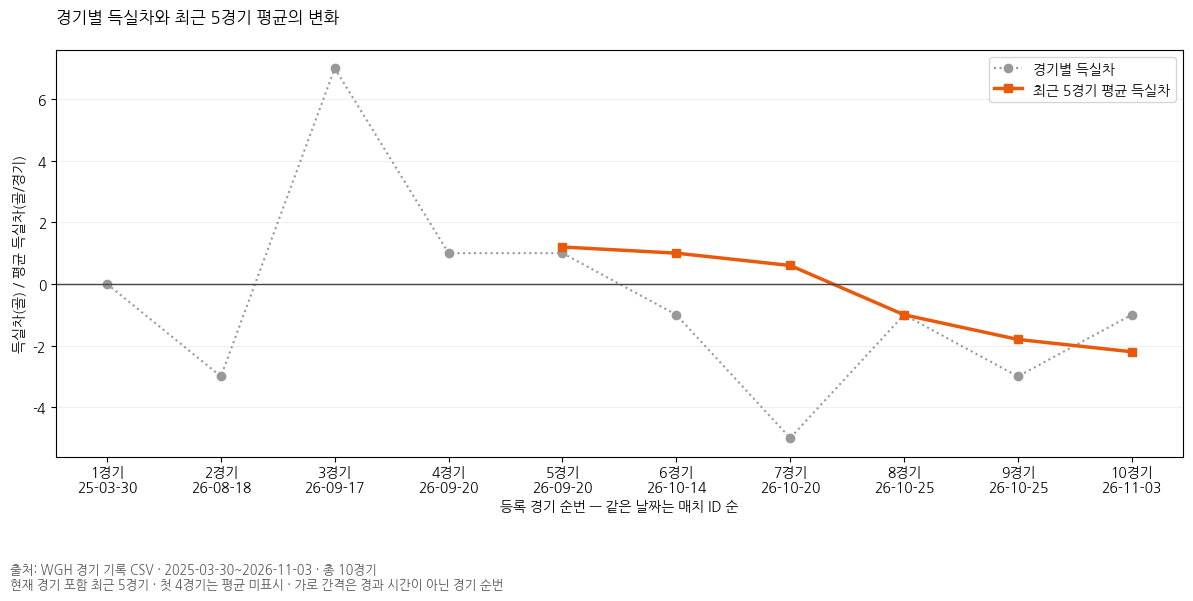

읽은 결과: 첫 5경기의 평균 득실차는 +1.20골/경기였고, 마지막 5경기는 -2.20골/경기였다.
주의: 등록된 10경기 안에서의 변화이며, 경기 간격·상대팀·경기 유형·경기 시간의 차이를 보정하지 않았다. 같은 날짜의 실제 경기 순서에 따라 중간 이동평균은 달라질 수 있다.


In [6]:
# 날짜순 정렬 — 같은 날짜는 매치 ID를 보조 기준으로 사용
trend = matches.copy()
trend["_정렬ID"] = pd.to_numeric(
    trend["매치 ID"], errors="raise"
)

trend = trend.sort_values(
    ["경기 날짜", "_정렬ID"]
).reset_index(drop=True)

trend["경기순번"] = np.arange(1, len(trend) + 1)

# 현재 경기까지 포함한 최근 5경기의 평균
trend["최근5경기평균"] = (
    trend["득실차"]
    .rolling(window=5, min_periods=5)
    .mean()
)

display(
    trend[[
        "경기순번", "경기 날짜", "상대팀",
        "우리 득점", "상대 득점", "득실차", "최근5경기평균"
    ]].round(2)
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    trend["경기순번"],
    trend["득실차"],
    color="#999999",
    marker="o",
    linestyle=":",
    label="경기별 득실차"
)

ax.plot(
    trend["경기순번"],
    trend["최근5경기평균"],
    color="#E8590C",
    marker="s",
    linewidth=2.5,
    label="최근 5경기 평균 득실차"
)

ax.axhline(0, color="#444444", linewidth=1)

ax.set_xticks(
    trend["경기순번"],
    [
        f"{int(row['경기순번'])}경기\n"
        f"{row['경기 날짜']:%y-%m-%d}"
        for _, row in trend.iterrows()
    ]
)

ax.set_title(
    "경기별 득실차와 최근 5경기 평균의 변화",
    loc="left",
    pad=20
)
ax.set_xlabel("등록 경기 순번 — 같은 날짜는 매치 ID 순")
ax.set_ylabel("득실차(골) / 평균 득실차(골/경기)")
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.01, 0.01,
    f"출처: WGH 경기 기록 CSV · {start}~{end} · 총 {len(trend)}경기\n"
    "현재 경기 포함 최근 5경기 · 첫 4경기는 평균 미표시 · "
    "가로 간격은 경과 시간이 아닌 경기 순번",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.11, 1, 1])

fig.savefig(
    "images/03_rolling_goal_difference.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

first_average = trend["최근5경기평균"].dropna().iloc[0]
last_average = trend["최근5경기평균"].dropna().iloc[-1]

print(
    f"읽은 결과: 첫 5경기의 평균 득실차는 "
    f"{first_average:+.2f}골/경기였고, "
    f"마지막 5경기는 {last_average:+.2f}골/경기였다."
)

print(
    "주의: 등록된 10경기 안에서의 변화이며, "
    "경기 간격·상대팀·경기 유형·경기 시간의 차이를 보정하지 않았다. "
    "같은 날짜의 실제 경기 순서에 따라 중간 이동평균은 달라질 수 있다."
)

읽은 결과: 첫 5경기의 평균 득실차는 +1.20골/경기였고, 마지막 5경기는 -2.20골/경기였다.
주의: 등록된 10경기 안에서의 변화이며, 경기 간격·상대팀·경기 유형·경기 시간의 차이를 보정하지 않았다. 같은 날짜의 실제 경기 순서에 따라 중간 이동평균은 달라질 수 있다.

## 기존 GitHub 분석과 추가 분석 비교

분석 대상:
https://github.com/YuNi-100/wgh-futsal-qa

기존 gateway/analysis_core.py는 경기 수, 승무패,
승률, 득실점 합계와 득실차를 집계한다.

이번 실습에서는 다음 세 가지 분석을 노트북에 추가했다.

1. 월별 경기당 평균 득점·실점
기존 월별 합계를 경기 수로 나누어 비교했다.
2026년 9월의 평균 득점은 3.67골로 가장 높았으나,
해당 월의 표본은 3경기였다.

2. 월별 승률의 Wilson 95% 신뢰구간
기존 승률에 표본 수에 따른 불확실성을 추가했다.
2026년 9월은 3전 전승으로 승률이 100%였지만,
95% 신뢰구간은 43.8~100.0%로 넓었다.

3. 최근 5경기 평균 득실차
개별 경기 결과에 이동평균을 추가해 흐름을 살펴봤다.
첫 5경기는 +1.20골/경기,
마지막 5경기는 −2.20골/경기였다.

## 분석의 한계

CSV에 포함된 등록 경기 10건만 분석했다.
경기 시간, 상대팀 수준, 경기 유형 차이는 보정하지 않았다.
같은 날짜의 실제 경기 순서는 확인되지 않았다.
결과를 전체 경기력이나 미래 성적에 대한 확정적 판단으로
해석하지 않는다.

이번 추가 분석은 별도 노트북에서 수행했으며,
기존 웹사이트 기능에 반영한 것은 아니다.

## AI 활용

ChatGPT로 기존 분석 코드 검토와 추가 기법 제안,
실습 코드 작성에 도움을 받았다.
Colab에서 코드를 실행하고 집계 표와 결과 수치를 확인했다.

In [7]:
from pathlib import Path
import zipfile
from google.colab import files

chart_files = [
    Path("images/01_monthly_average_goals.png"),
    Path("images/02_monthly_winrate_ci.png"),
    Path("images/03_rolling_goal_difference.png")
]

for file in chart_files:
    assert file.exists(), f"파일이 없습니다: {file}"
    assert file.stat().st_size > 0, f"빈 파일입니다: {file}"
    print(f"확인: {file.name}")

with zipfile.ZipFile("WGH_추가분석_차트3장.zip", "w") as archive:
    for file in chart_files:
        archive.write(file, arcname=file.as_posix())

files.download("WGH_추가분석_차트3장.zip")

확인: 01_monthly_average_goals.png
확인: 02_monthly_winrate_ci.png
확인: 03_rolling_goal_difference.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>